<a href="https://colab.research.google.com/github/RafaellsAlmeida/RafaellsAlmeida/blob/main/LoureiroSandimdeAlmeida_Rafael_Week06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<!-- ISM4543-BANNER -->
# Integrative Assignment on Week 06 Material — ClearView Auto Insurance
## K-nearest neighbours for a retention call list

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, October 5, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

> **Why "integrative"?** This assignment does not test this week's technique in
> isolation. It expects you to bring forward the data preparation, evaluation, and
> communication skills from earlier weeks and combine them with what you learned
> this week. Marks are lost for a technically correct model presented without
> framing, verification, or interpretation.

---

## The client: ClearView Auto Insurance

**ClearView Auto Insurance** is a regional auto insurer with about **12,000 policyholders** in three
states. Policies renew once a year, so about **1,000 come up for renewal every month**, and about **one
policyholder in four leaves** at renewal instead of renewing. That is roughly 260 departures a month,
and replacing each one costs ClearView about \$2,800 in marketing and onboarding: **more than
\$700,000 a month**.

ClearView has a small retention team that phones policyholders before their renewal date, with a
discount to offer. It cannot phone everyone, and today it works through the renewal list in no
particular order. Last year it tried a rule instead: offer the discount to everyone whose premium was
going up by more than 10%, about a quarter of each month's renewals. Retention barely moved. Roughly
two in three of those discounts went to people who were going to renew anyway, and six in ten of the
people who left never got one. The digital team has its own theory: policyholders with an online
account are the loyal ones, so the team should leave them off the list.

ClearView has now pulled the records of **2,000 policyholders who came up for renewal last year**:
thirteen things it knew about each one before the renewal date, and whether they renewed or left.
Three people want answers from it.

- **Maria Chen, VP of Retention:** *"My team can make about **300 calls a month**. When we're
  short-staffed it drops to **150**; with temporary help over the summer we could reach **500**. I don't
  need a yes or no on every policyholder. I need to know who to call first, and how far down the
  list my calls will get."*
- **James Okafor, CFO:** *"A retention call costs us about **\$200**, agent time plus the discount.
  Replacing a policyholder who leaves costs about **\$2,800** in marketing and onboarding. For
  planning, assume a call keeps a policyholder who was going to leave. I know it doesn't always, but
  it gives us one number to plan with."*
- **Aisha Patel, Head of Analytics:** *"We already have a logistic regression, built the way you built
  one in Week 5; that is the benchmark. I suspect some churn patterns aren't straight lines: people
  with no claims and people with several claims both seem to leave. KNN might catch that. But KNN
  uses every column you give it, and I'm not convinced all thirteen of ours carry anything, the
  online account included."*

**The decision the model feeds** is made every month: **which policyholders the team calls, and in what
order**. Staffing sets the number of calls, not the model. What Maria needs is the month's renewals
sorted from most to least likely to leave; your job is to build that list, show how many leavers her
calls would reach at each staffing level, and say what that is worth at James's figures.

### The questions you will answer

| # | Question | Asked by | Worked out in | Answered in |
|---|---|---|---|---|
| 1 | What does a call cost, what does a missed leaver cost, and how should one call list be judged against another? | James and Maria | Part 1 | 1.2, 1.3 |
| 2 | Which of the thirteen columns separate leavers from renewers, and which carry nothing? Is the digital team right about online accounts? | Aisha | Part 2 | 2.3 |
| 3 | Does KNN need the features scaled, and do the columns that carry nothing hurt it? | Aisha | Parts 3 and 4 | 3.3, 4.2 |
| 4 | How many neighbors should KNN use, and why does the answer depend on how the list is scored? | Aisha | Part 5 | 5.2 |
| 5 | At 150, 300 and 500 calls a month, how many leavers does the list reach, and what does it save? | Maria and James | Part 6 | 6.2 |
| 6 | KNN or the logistic regression benchmark? | Aisha | Part 7 | 7.2 |

Parts 8 to 10 are about you: three questions answered without AI, two errors to catch, and your
reflection and AI Usage Report.

### About this data

File `insurance_churn.csv`: **2,000 rows × 14 columns**, a sample of 2,000 of the policyholders who
came up for renewal last year, one row each, no missing values. It loads by URL in Part 2. The insurer, the people and the
decisions are the setting; the policyholders are **simulated**, so the data is clean and the patterns
are there to be found.

| Column | Meaning |
|---|---|
| `customer_age` | Policyholder's age in years (18 to 80) |
| `years_as_customer` | Years with ClearView (0.5 to 25) |
| `monthly_premium` | Monthly premium, dollars (\$80 to \$600) |
| `num_policies` | Number of ClearView policies the policyholder holds (1 to 4) |
| `policy_type` | Coverage level: `basic`, `standard` or `premium` (text) |
| `claims_last_year` | Claims filed in the past year (0 to 5) |
| `claim_amount_avg` | Average amount per claim, dollars; 0 when there were no claims (\$0 to \$21,372) |
| `customer_service_calls` | Calls to customer service in the past year (0 to 8) |
| `online_account_active` | 1 if the policyholder uses ClearView's online account, 0 if not |
| `auto_pay_enrolled` | 1 if the premium is paid automatically, 0 if not |
| `satisfaction_score` | Most recent satisfaction survey score (1 to 10) |
| `late_payments` | Late premium payments in the past year (0 to 5) |
| `premium_increase_pct` | Change in the premium quoted for renewal, percent (−5 to 30; negative is a decrease) |
| `churned` | 1 if the policyholder left at renewal, 0 if they renewed (**the target**) |

### How the work flows

Frame the problem from the costs (Part 1) before you look at the data. Split first, then explore
**only the training rows** (Part 2): which columns go into the distance is a choice, and choices are
made without the test set. (Week 5 explored all the rows; here the exploration picks the features, so
it moves after the split.) Build one `Pipeline` that scales and fits, and check what scaling buys
(Part 3) and what the flat columns cost (Part 4). Choose K by **cross-validation on the training
rows**, with a score that matches Maria's decision (Part 5). Only then score the test set, **once**,
at Maria's three staffing levels (Part 6), and set the result beside Aisha's benchmark (Part 7).
Parts 8 to 10 are written in your own words, and Part 8 without AI.

### Video walkthrough (required)

Record a 3–5 minute video in your own running notebook, presenting to Maria Chen, James Okafor and
Aisha Patel.
What it must show is listed under **Video walkthrough** at the end of this notebook.

### Instructions

- Use AI for the code; write every interpretation in your own words.
- Follow this week's workflow from the slides and the lecture notes. Nothing later in the course is
  needed; if you find yourself reaching for something we have not covered, you have
  overcomplicated it.
- Every decision refers back to ClearView's costs and people above.
- Part 8 is completed without AI.

---

## Setup

Run this cell first. It also defines `churners_in_top`, the lecture notes' helper (Section 4) that
ranks policyholders by probability and counts the leavers in the top share of the list.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)


def churners_in_top(proba, y_true, top_share=0.30):
    # Rank by predicted probability, take the top share, count the leavers among them
    n_calls = int(round(top_share * len(y_true)))
    order = np.argsort(-np.asarray(proba), kind='stable')   # highest probability first
    # kind='stable': policyholders with the same probability keep their order in the data, so
    # which of several tied policyholders make the cut is arbitrary (Part 6 asks about this).
    return int(np.asarray(y_true)[order[:n_calls]].sum()), n_calls


print("Libraries loaded successfully!")

Libraries loaded successfully!


---

## Part 1: Problem Framing

### 1.1 Problem Statement

Write a 3–5 sentence problem statement. What are we predicting, for whom, and what decision does it
feed? What will define success?

The business is losing 700,000 dollars a month worth of customers churning, they have a team with the capacity to end churn by allocating the 300 calls to the actual customers that are most likely to churn (~260) and we need to use data science to predict those customers most likely to churn and create a formula that will be able to maximize profits with the least amount of risk.


### 1.2 Costs

Using James's figures, and taking **leaving (`churned = 1`) as the positive class**:

- What does a call to a policyholder who would have renewed anyway cost ClearView? And a call to
  one who was going to leave?

  Both calls cost $200. Under the planning assumption, a call to someone who would have left also
  avoids a $2,800 replacement cost, so its net benefit is $2,600 relative to not calling.

- What does a leaver the team never calls cost?

  $2,800 in replacement cost.

- Write the cost of a month's list of **N** calls that reaches **C** of the month's **M** leavers.

  **Total cost = $200N + $2,800(M − C).**

- Under James's planning assumption, above what chance of leaving does a single call pay for itself?

  The break even point is $200 / $2,800 = **0.0714, or 7.14%**. The expected savings exceed the
  call cost when the true probability of leaving is greater than 7.14%.


### 1.3 How to judge a call list

Maria's number of calls is set by staffing, not by the model. For a **fixed** number of calls, what
makes one list better than another? Why is accuracy the wrong way to judge it?

For a fixed number of calls, you want the highest precision possible. Precision measures, out of everyone you call, how many are actually going to leave, so higher precision means fewer wasted calls. Accuracy is the wrong metric because it also rewards correctly predicting people who will stay, even though those predictions do not affect the fixed call list. In this setting, the model should be judged by how concentrated the true leavers are in the top \(N\) customers selected for calling.

---

## Part 2: Data Understanding

In [2]:
# Load the policyholder data from the course data repo
DATA_URL = 'https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week06'

df = pd.read_csv(f'{DATA_URL}/insurance_churn.csv')

print(f"Dataset shape: {df.shape}")
print(f"Churn rate: {df['churned'].mean():.1%}")
df.head()

Dataset shape: (2000, 14)
Churn rate: 26.0%


,customer_age,years_as_customer,monthly_premium,num_policies,policy_type,claims_last_year,claim_amount_avg,customer_service_calls,online_account_active,auto_pay_enrolled,satisfaction_score,late_payments,premium_increase_pct,churned
0,47,2.6,277.93,1,basic,1,9117.85,1,0,1,7,0,-4.1,0
1,40,0.5,230.82,1,standard,2,3219.61,4,0,0,6,0,8.3,1
2,49,2.1,455.53,1,standard,0,0.00,3,1,0,9,1,4.0,0
3,60,0.6,100.31,4,basic,1,500.00,3,1,1,6,0,-1.1,0
4,39,8.3,299.97,2,standard,2,1177.86,2,1,0,5,0,0.1,1


### 2.1 Split first

Split `df` into `train_df` and `test_df` with `test_size=0.2`, `stratify` on `churned` and
`random_state=42`, and check that the churn rate is the same in both. Everything until Part 6 uses
`train_df` only.

In [3]:
# Split before using the data to inspect or select features.
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df['churned'], random_state=42
)
for name, part in [('Train', train_df), ('Test', test_df)]:
    print(f"{name}: {len(part)} rows, {int(part['churned'].sum())} leavers, "
          f"churn rate {part['churned'].mean():.1%}")


Train: 1600 rows, 416 leavers, churn rate 26.0%
Test: 400 rows, 104 leavers, churn rate 26.0%


### 2.2 Which columns separate leavers from renewers?

On the **training rows only**, compare the churn rate across each column's values: group by the
value for a column with ten or fewer values, and by quartile with `pd.qcut(..., 4)` (Week 3) for the
rest. `claim_amount_avg` is 0 for everyone with no claims, so its quartile edges repeat: pass
`duplicates='drop'`. Print each group's size beside its rate, because a rate from a handful of
policyholders means little. Then print each numeric column's correlation with `churned`
(`train_df.corr(numeric_only=True)`, since `policy_type` is text).

*Use AI to help you write the code, but interpret the results yourself.*

In [4]:
import pandas as pd

# Exclude the target variable 'churned'
columns_to_explore = [col for col in train_df.columns if col != 'churned']

print("=== Group Analysis on Training Data ===\n")

for col in columns_to_explore:
    print(f"--- Column: {col} ---")

    # Determine if we group by exact value or by quartile
    num_unique = train_df[col].nunique()
    is_numeric = pd.api.types.is_numeric_dtype(train_df[col])

    if num_unique <= 10 or not is_numeric:
        # Group by exact value
        groups = train_df.groupby(col)
    else:
        # Group by quartile with duplicates='drop' for repeated edges
        try:
            quartiles = pd.qcut(train_df[col], q=4, duplicates='drop')
            groups = train_df.groupby(quartiles)
        except Exception as e:
            print(f"Could not bin {col} into quartiles: {e}")
            continue

    # Calculate size and churn rate for each group
    summary = groups['churned'].agg(size='count', churn_rate='mean')
    summary['churn_rate'] = summary['churn_rate'].map(lambda x: f"{x:.1%}")
    display(summary)
    print("\n")

print("=== Numeric Correlations with Churned ===")
correlations = train_df.corr(numeric_only=True)['churned'].sort_values(ascending=False)
display(correlations)

=== Group Analysis on Training Data ===

--- Column: customer_age ---


,size,churn_rate
customer_age,,
"(17.999, 34.0]",424,29.5%
"(34.0, 42.0]",413,28.8%
"(42.0, 50.0]",393,20.1%
"(50.0, 80.0]",370,25.1%




--- Column: years_as_customer ---


,size,churn_rate
years_as_customer,,
"(0.499, 1.4]",408,35.3%
"(1.4, 3.4]",402,28.4%
"(3.4, 6.8]",392,20.4%
"(6.8, 25.0]",398,19.6%




--- Column: monthly_premium ---


...

,size,churn_rate
late_payments,,
0,883,26.6%
1,534,25.5%
2,151,27.2%
3,26,7.7%
4,4,50.0%
5,2,0.0%




--- Column: premium_increase_pct ---


,size,churn_rate
premium_increase_pct,,
"(-5.001, -0.5]",401,19.0%
"(-0.5, 5.4]",411,18.5%
"(5.4, 10.7]",390,31.8%
"(10.7, 30.0]",398,35.2%




=== Numeric Correlations with Churned ===


,churned
churned,1.000000
premium_increase_pct,0.150461
monthly_premium,0.076301
customer_service_calls,0.072858
claims_last_year,0.026795
online_account_active,-0.016256
late_payments,-0.023128
claim_amount_avg,-0.023784
customer_age,-0.053804
auto_pay_enrolled,-0.078311


### 2.3 EDA summary

- **Which columns separate leavers from renewers, and which look flat?**
  `num_policies`, `satisfaction_score`, and `years_as_customer` have negative associations with
  churn; `premium_increase_pct` has a positive one. `online_account_active`, `claim_amount_avg`,
  and `late_payments` look weak in these training summaries. I removed those three from KNN's
  distance calculation and tested the effect out of fold in Part 4.

- **Is the digital team right that online-account holders are the loyal ones?**
  The observed churn rate is 26.8% without an active online account and 25.4% with one. That small
  difference does not support leaving account holders off the call list. These descriptive rates
  alone do not establish statistical significance or a causal effect.

- **Do the correlation and table agree for claims and service calls?**
  Both correlations are positive, but weak: about 0.027 for `claims_last_year` and 0.073 for
  `customer_service_calls`. The groups are not strictly increasing; for example, the one-claim
  group has a lower churn rate than the zero-claim group. The highest count groups are tiny, so I
  would not treat their extreme rates as a stable pattern. I kept both columns for the KNN comparison.


---

## Part 3: Scaling

### 3.1 Features and the Pipeline

Build `X_train`, `y_train`, `X_test`, `y_test` from `train_df` and `test_df`. One-hot encode
`policy_type` with `pd.get_dummies(..., columns=['policy_type'], dtype=int)` (Week 3). It learns
nothing from the rows, so encoding each part separately is safe, but check that both parts end up
with the same columns. Then build a `Pipeline` of `StandardScaler` and
`KNeighborsClassifier(n_neighbors=41)`. K = 41 is a placeholder near the square root of the 1,600
training rows, the deck's starting point; Part 5 chooses K.

In [5]:
# X_train, y_train, X_test, y_test, with policy_type one-hot encoded
# One-hot encode the categorical column 'policy_type' on the datasets
train_encoded = pd.get_dummies(train_df, columns=['policy_type'], dtype=int)
test_encoded = pd.get_dummies(test_df, columns=['policy_type'], dtype=int)

X_train = train_encoded.drop(columns=['churned'])
y_train = train_encoded['churned']
X_test = test_encoded.drop(columns=['churned'])
y_test = test_encoded['churned']

# Check X_train and X_test have the same columns
check = (X_train.columns == X_test.columns).all()
print(f"X_train and X_test have identical columns: {check}")

# Pipeline: StandardScaler, then KNeighborsClassifier(n_neighbors=41)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=41))
])

# Fit the pipeline on the scaled training rows
pipe.fit(X_train, y_train)
print("Pipeline successfully fitted on the training data!")

X_train and X_test have identical columns: True
Pipeline successfully fitted on the training data!


### 3.2 Does scaling matter?

Judge each list on the **training rows, out of fold**: `cross_val_predict(..., cv=5,
method='predict_proba')` gives every training row a probability from a model that never saw it (the
deck's *Out-of-Fold Probabilities* slide). Count the leavers in the top 30% (480 of the 1,600 rows)
with `churners_in_top`, once for the Pipeline and once for `KNeighborsClassifier(n_neighbors=41)` on
unscaled features. Print what a random 480 would hold, and each feature's standard deviation on the
training rows.

In [6]:
# Out-of-fold probabilities on the training rows, scaled (Pipeline) and unscaled (KNN alone)
from sklearn.model_selection import cross_val_predict

# Scaled out-of-fold probabilities using the pipeline
proba_scaled = cross_val_predict(pipe, X_train, y_train, cv=5, method='predict_proba')[:, 1]

# Unscaled out-of-fold probabilities using KNN directly
knn_unscaled = KNeighborsClassifier(n_neighbors=41)
proba_unscaled = cross_val_predict(knn_unscaled, X_train, y_train, cv=5, method='predict_proba')[:, 1]

# Leavers in the top 30% for each, and for a random list of the same length
leavers_scaled, n_calls = churners_in_top(proba_scaled, y_train, top_share=0.30)
leavers_unscaled, _ = churners_in_top(proba_unscaled, y_train, top_share=0.30)

# A random selection of the same length (n_calls) expects to find: n_calls * training churn rate
random_expected = n_calls * y_train.mean()
actual_total_leavers = y_train.sum()

print(f"Total training leavers: {actual_total_leavers} (out of {len(y_train)})")
print(f"Calls made (30% of training rows): {n_calls}")
print(f"Leavers captured with Scaling (Pipeline): {leavers_scaled}")
print(f"Leavers captured without Scaling: {leavers_unscaled}")
print(f"Leavers captured with a random selection: {random_expected:.1f}")
print()

# Each feature's standard deviation on the training rows
print("=== Feature Standard Deviations (Training Rows) ===")
std_devs = X_train.std().sort_values(ascending=False)
print(std_devs)

Total training leavers: 416 (out of 1600)
Calls made (30% of training rows): 480
Leavers captured with Scaling (Pipeline): 211
Leavers captured without Scaling: 153
Leavers captured with a random selection: 124.8

=== Feature Standard Deviations (Training Rows) ===
claim_amount_avg          2178.575665
monthly_premium             77.967342
customer_age                11.704342
premium_increase_pct         7.388136
years_as_customer            4.662591
satisfaction_score           1.782890
customer_service_calls       1.268076
num_policies                 0.959098
claims_last_year             0.880897
late_payments                0.764172
policy_type_standard         0.498700
auto_pay_enrolled            0.496154
online_account_active        0.492768
policy_type_basic            0.472138
policy_type_premium          0.402451
dtype: float64


### 3.3 What scaling changed

The scaled top 480 contains **211 leavers**, versus **153** without scaling: 58 more. The dollar
scale of `claim_amount_avg` dominates unscaled Euclidean distance (training standard deviation about
$2,179, far above the other columns). That is especially unhelpful here because its training churn
summary is nearly flat. Standardizing the columns prevents dollar magnitude alone from determining
which customers KNN treats as neighbors.


---

## Part 4: Which Features Go In?

### 4.1 Remove the flat columns

Repeat the scaled out-of-fold count at K = 41 **without** the columns your Part 2 table found flat
(if you drop `policy_type`, drop all three of its one-hot columns). Keep everything else the same.
Store the columns you keep in a list, `features`, for the rest of the notebook.

In [7]:
# features = the columns you keep
# Dropping 'online_account_active', 'claim_amount_avg', 'late_payments' as they are flat/weak
flat_cols = ['online_account_active', 'claim_amount_avg', 'late_payments']
features = [col for col in X_train.columns if col not in flat_cols]

# Leavers in the top 30%, out of fold, K = 41: all columns vs. features
# Subset data to only kept features
X_train_features = X_train[features]

# Define the pipeline on the selected features
pipe_features = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=41))
])

# Compute out-of-fold probabilities on selected features
proba_features = cross_val_predict(pipe_features, X_train_features, y_train, cv=5, method='predict_proba')[:, 1]
leavers_features, n_calls = churners_in_top(proba_features, y_train, top_share=0.30)

print(f"Leavers in top 30% with ALL columns: {leavers_scaled}")
print(f"Leavers in top 30% with SELECTED features: {leavers_features}")
print(f"Difference: {leavers_features - leavers_scaled} leavers captured")
print(f"Active features being used: {features}")

Leavers in top 30% with ALL columns: 211
Leavers in top 30% with SELECTED features: 215
Difference: 4 leavers captured
Active features being used: ['customer_age', 'years_as_customer', 'monthly_premium', 'num_policies', 'claims_last_year', 'customer_service_calls', 'auto_pay_enrolled', 'satisfaction_score', 'premium_increase_pct', 'policy_type_basic', 'policy_type_premium', 'policy_type_standard']


### 4.2 Why the flat columns mattered

Removing the three weak columns raised the top-480 out-of-fold count from **211 to 215**, a gain of
four leavers in this comparison. KNN uses every retained column to measure distance. A scaled column
with little relationship to churn can still shift who is considered a neighbor; it is not ignored
automatically. The gain is modest, so it is evidence for this feature set rather than a guarantee
that removing these columns will improve every future sample.


---

## Part 5: Choosing K

### 5.1 The search

On your `features`, for K = 1, 5, 11, 21, 41, 61, 81, 101 and 151, compute two scores by 5-fold
cross-validation on the training rows:

- **F1 at the vote**: `cross_val_score(pipe, ..., cv=5, scoring='f1')`, which scores `predict()`;
- **leavers in the top 30%** of the out-of-fold probabilities.

Print both in a table and plot both against K, as the deck's *The Score Must Match the Decision*
slide does.

,K,CV F1-Score,Leavers in Top 30%
0,1,0.413723,186
1,5,0.364075,199
2,11,0.283613,213
3,21,0.205449,218
4,41,0.097919,215
5,61,0.023641,215
6,81,0.009524,215
7,101,0.004762,220
8,151,0.000000,221


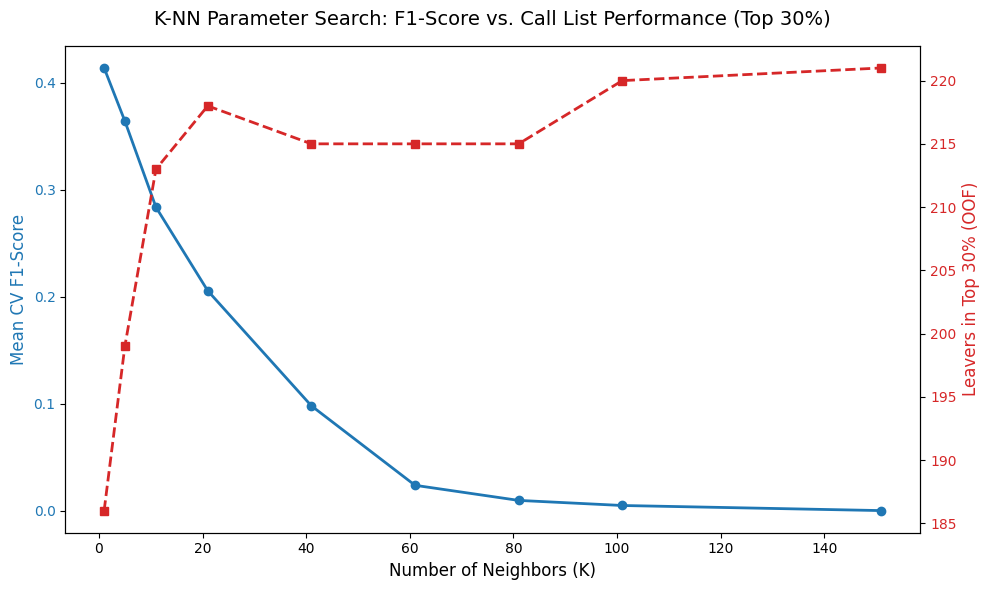

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# Define search space for K
k_values = [1, 5, 11, 21, 41, 61, 81, 101, 151]

results = []

for k in k_values:
    # Define pipeline with the current K on kept features
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    # 1. F1 score at the default threshold (using cross_val_score on predict())
    f1_scores = cross_val_score(pipe_k, X_train_features, y_train, cv=5, scoring='f1')
    mean_f1 = f1_scores.mean()

    # 2. Out-of-fold probabilities to measure leavers in the top 30% of calls
    proba_oof = cross_val_predict(pipe_k, X_train_features, y_train, cv=5, method='predict_proba')[:, 1]
    captured_leavers, _ = churners_in_top(proba_oof, y_train, top_share=0.30)

    results.append({
        'K': k,
        'CV F1-Score': mean_f1,
        'Leavers in Top 30%': captured_leavers
    })

# Convert to a DataFrame for clean presentation
results_df = pd.DataFrame(results)
display(results_df)

# Plot both metrics against K
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot F1 on primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Number of Neighbors (K)', fontsize=12)
ax1.set_ylabel('Mean CV F1-Score', color=color, fontsize=12)
ax1.plot(results_df['K'], results_df['CV F1-Score'], marker='o', color=color, linewidth=2, label='CV F1')
ax1.tick_params(axis='y', labelcolor=color)

# Create a secondary y-axis for captured leavers
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Leavers in Top 30% (OOF)', color=color, fontsize=12)
ax2.plot(results_df['K'], results_df['Leavers in Top 30%'], marker='s', color=color, linewidth=2, linestyle='--', label='Leavers in Top 30%')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-NN Parameter Search: F1-Score vs. Call List Performance (Top 30%)', fontsize=14, pad=15)
fig.tight_layout()
plt.show()

### 5.2 Which K, and why the scores disagree

The default-vote F1 score selects **K = 1** (F1 = 0.414), while the call-list metric selects
**K = 151** (221 leavers in the top 30% of the out-of-fold ranking). These scores disagree because
F1 evaluates a fixed 0.5 class-vote threshold, while Maria has a fixed number of calls and needs a
ranking of probabilities. A large K can produce useful ordering even when every probability is below
0.5, so it can have a low vote-based F1 while still putting more leavers near the top of the list.

I choose **K = 151** for Maria because the top-30% metric matches the decision she actually controls:
how many leavers are reached with a fixed call capacity. The choice is based on out-of-fold training
predictions; the test set is reserved for the final comparison.


---

## Part 6: The Test Set, Once

### 6.1 Maria's three staffing levels

Refit your chosen Pipeline on all the training rows, on `features`, and score the test set **once**.
The 400 test policyholders stand in for 400 of a month's 1,000 renewals, so Maria's 150, 300 and 500
calls a month become **60, 120 and 200** calls here. Rank the test policyholders by `predict_proba`
and, for each staffing level, report:

- leavers reached (out of the test set's leavers), recall and precision;
- the vote share of the last policyholder called, and how many test policyholders share it;
- the cost of the list (your 1.2 formula), and of a random list of the same length, which reaches
  N × (the test set's churn rate) leavers on average.

Work in the 400 test policyholders (M is the test set's leavers); say so if you scale to a month.
Add the cost of calling nobody, and count how many test policyholders `predict()` flags.

In [9]:
# Final K selected from the training-only top-30% comparison
chosen_k = 151
final_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=chosen_k))
])
final_knn.fit(X_train_features, y_train)
test_proba = final_knn.predict_proba(X_test[features])[:, 1]
test_pred = final_knn.predict(X_test[features])

def list_report(proba, y_true, n):
    order = np.argsort(-np.asarray(proba), kind='stable')
    called = order[:n]
    reached = int(np.asarray(y_true)[called].sum())
    cutoff = float(np.asarray(proba)[called[-1]])
    ties = int((np.asarray(proba) == cutoff).sum())
    M = int(np.asarray(y_true).sum())
    random_reached = n * float(np.asarray(y_true).mean())
    cost = 200 * n + 2800 * (M - reached)
    random_cost = 200 * n + 2800 * (M - random_reached)
    return {
        'calls': n, 'leavers_reached': reached, 'recall': reached / M,
        'precision': reached / n, 'last_vote_share': cutoff,
        'number_sharing_cutoff': ties, 'cost': cost,
        'random_cost': random_cost, 'saving_vs_random': random_cost - cost,
        'saving_vs_nobody': 2800 * M - cost,
    }

test_reports = pd.DataFrame([list_report(test_proba, y_test.to_numpy(), n) for n in [60, 120, 200]])
display(test_reports)
print(f'Test-set leavers M = {int(y_test.sum())}')
print(f'Calling nobody costs ${2800 * int(y_test.sum()):,.0f}.')
print(f'Number flagged by predict(): {int(test_pred.sum())}')


,calls,leavers_reached,recall,precision,last_vote_share,number_sharing_cutoff,cost,random_cost,saving_vs_random,saving_vs_nobody
0,60,30,0.288462,0.500000,0.324503,7,219200,259520.0,40320.0,72000
1,120,56,0.538462,0.466667,0.284768,10,158400,227840.0,69440.0,132800
2,200,79,0.759615,0.395000,0.245033,16,110000,185600.0,75600.0,181200


Test-set leavers M = 104
Calling nobody costs $291,200.
Number flagged by predict(): 0


### 6.2 What Maria and James get

The test set contains 104 leavers. KNN reaches 30, 56, and 79 at 60, 120, and 200 calls. Its cost is
$219,200, $158,400, and $110,000, compared with random-list expected costs of $259,520, $227,840,
and $185,600. Calling nobody costs $291,200 in this 400-person test sample.

The additional 80 calls from the 120-call to the 200-call plan reach 23 more leavers in this sample
and reduce observed cost by $48,400. The last KNN vote shares are about 32.5%, 28.5%, and 24.5%.
They exceed the theoretical 7.14% break even probability, but KNN vote shares have not been
calibrated as probabilities here, so that comparison alone cannot prove the marginal calls will
pay off in a future month. The ranking used stable row order when people had the same vote share;
the table reports how many shared each cutoff (7, 10, and 16 respectively).


---

## Part 7: KNN or the Benchmark?

### 7.1 Aisha's benchmark

Build the benchmark the Week 5 way: a `Pipeline` of `StandardScaler` and
`LogisticRegression(class_weight='balanced')`, on **all** the columns. Choose between it and your KNN
the way K was chosen: by the leavers in the top 30%, out of fold on the training rows. Then report both
on the test set at 60, 120 and 200 calls, once: the test set reports, it does not choose. Also fit the
benchmark on your KNN's `features`: does dropping the flat columns change it as much as it changed
KNN?

In [10]:
# Logistic-regression benchmark, evaluated with the same top-30% decision metric
log_all = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=2000))
])
log_features = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=2000))
])

log_all_oof = cross_val_predict(log_all, X_train, y_train, cv=5, method='predict_proba')[:, 1]
log_features_oof = cross_val_predict(log_features, X_train_features, y_train, cv=5, method='predict_proba')[:, 1]
knn_oof = cross_val_predict(final_knn, X_train_features, y_train, cv=5, method='predict_proba')[:, 1]
comparison_oof = pd.DataFrame({
    'model': ['KNN selected features', 'Logistic all columns', 'Logistic selected features'],
    'OOF leavers in top 30%': [churners_in_top(knn_oof, y_train)[0],
                               churners_in_top(log_all_oof, y_train)[0],
                               churners_in_top(log_features_oof, y_train)[0]]
})
display(comparison_oof)

log_all.fit(X_train, y_train)
log_features.fit(X_train_features, y_train)
model_test_probs = {
    'KNN selected features': test_proba,
    'Logistic all columns': log_all.predict_proba(X_test)[:, 1],
    'Logistic selected features': log_features.predict_proba(X_test[features])[:, 1],
}
comparison_test = pd.DataFrame([
    {'model': name, **{f'leavers at {n} calls': churners_in_top(prob, y_test, top_share=n / len(y_test))[0]
                       for n, prob in [(60, probs), (120, probs), (200, probs)]}}
    for name, probs in model_test_probs.items()
])
display(comparison_test)


,model,OOF leavers in top 30%
0,KNN selected features,221
1,Logistic all columns,223
2,Logistic selected features,223


,model,leavers at 60 calls,leavers at 120 calls,leavers at 200 calls
0,KNN selected features,30,56,79
1,Logistic all columns,33,55,74
2,Logistic selected features,33,52,73


### 7.2 Recommendation to Aisha

I recommend **logistic regression on all columns** for the initial call list. The training-only
top-30% comparison reaches 223 leavers for that benchmark versus 221 for the selected KNN, which is
the comparison allowed to choose the model. Removing the weak columns leaves logistic regression at
223 in this comparison, while it changes KNN's K = 41 ranking by four leavers.

The held-out test results are mixed: logistic regression reaches 33, 55, and 74 leavers at 60, 120,
and 200 calls; KNN reaches 30, 56, and 79. Those small, capacity-dependent differences do not show a
clear winner on this one test set and should not be used to reverse the training-only choice.
Logistic regression gives coefficients whose directions can be inspected; KNN gives a neighbor-based
ranking that may capture patterns a linear model misses. I would monitor both on later renewals.


---

## Part 8: Understanding Demonstration

**Answer these questions WITHOUT AI assistance.** They test your understanding of the material from
the slides and lecture notes.

**Q1:** Aisha's intern says: *"KNN has no coefficients, so scaling can't matter to it."* Explain
what scaling changes for KNN, using one column from this dataset.

*Your answer:*

**Q2:** A colleague says: *"K = 1 is perfect on the training rows, and it has the best
cross-validated F1. It is clearly the best K."* Both facts are true. Explain why neither one makes
K = 1 the right K for Maria's list.

*Your answer:*

**Q3:** Maria asks why her call list doesn't just come from `model.predict()`. Explain what
`predict()` does with your K, and why it flagged so few of the 400 test policyholders.

*Your answer:*

---

## Part 9: Critical Analysis

Identify the error in each scenario and explain what should be done instead.

**Error 1:** A colleague chooses K with this loop:
```python
best_k, best_count = None, 0
for k in [1, 5, 11, 21, 41, 61, 81, 101, 151]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    count, _ = churners_in_top(pipe.predict_proba(X_test)[:, 1], y_test)
    if count > best_count:
        best_k, best_count = k, count
print(f"Best K = {best_k}: {best_count} leavers in the top 120 test policyholders")
```

*What is wrong, and what should be done instead?*

This loop uses test labels to select K. That makes the test score optimistic because the test set is
no longer an independent check. I would rank training rows using out-of-fold probabilities for each
candidate K, choose K from those training results, refit once on all training rows, and score the
test set only after the choice is fixed.


**Error 2:** Another colleague remembers Week 5's rule, *choose on the training rows*, and
writes:
```python
for k in [1, 5, 11, 21, 41]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    count, n_calls = churners_in_top(pipe.predict_proba(X_train)[:, 1], y_train)
    print(f"K = {k:3d}: {count} leavers in the top {n_calls}")
```
K = 1 puts all 416 training leavers in the top 480, so they choose K = 1.

*Why does K = 1 look perfect here, and what should be done instead?*

At K = 1, each training customer is their own nearest neighbor, so evaluating the same rows used to
fit the model gives a misleadingly perfect ranking. Use out-of-fold probabilities: each row must be
predicted by a model that did not train on that row. Then compare how many leavers appear in the top
30% of that out-of-fold ranking.


---

## Part 10: Reflection and AI Usage Report

The separate AI Usage Report contains the prompt record, results, checks, and corrections. The
Gemini conversation shown beside this notebook is attached separately as
`Almeida_Rafael_Week06_Gemini_Conversation_Export.txt`.

### 10.1 Prompt evolution log

Attempt 1: "fix this code"
   Result: AI described one-hot encoding and a scaled KNN pipeline; that helped the code run.
   How I checked it: the train and test feature columns matched, and the pipeline fit.
   Problem: the request was too vague to say how to compare K values for Maria's fixed call list.
Attempt 2: I specified the nine K values and asked for both five-fold F1 and the out-of-fold
   leavers in the top 30%, with a table and plot.
   Result: K=1 had the best F1 (0.414), but K=151 found the most leavers in the top 30% (221).
   How I checked it: I reran the notebook and compared the two columns in the K-search table.

### 10.2 Confidence self-assessment

| Topic | 1-5 | What would move this up one point? |
|---|---:|---|
| KNN | 4 | It would move this up a point if I was exposed to multiple different scenarios of KNN usage and it's impact. |

### 10.3 AI Usage Report

See the separate **ISM 4543 — Week 06 AI Usage Report** for the tools used, saved prompts,
calculations, verification, and revisions.


---

## Video walkthrough

**3–5 minutes, hard stop at five.** Record it in **your own running notebook**, and show:

1. **the cost of a call and of a missed leaver**, your break-even (1.2), and how you judge a call
   list (1.3);
2. **your K plot** (5.1), the K you chose, and why F1 at the vote would have chosen differently (5.2);
3. **your test-set table** at Maria's three staffing levels, scored **once** (6.1), and what it says
   about the temporary help (6.2);
4. **your recommendation to Aisha** (7.2), in one sentence.

Talk the way you would explain it to a colleague; do not read a script. Graders compare the video with
the plots in your notebook.

---

## Before you submit

- [ ] **Runtime → Restart session and run all** (in Colab), top to bottom, with no errors. Save the file *after* it has
      run, so your outputs are in what you upload.
- [ ] Every *Your answer* prompt is filled in, in **your own words** — Part 8 without AI.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the checking, the
      re-prompting, and one thing you rejected -- **plus the full conversation export attached as a
      separate file.** The written account alone does not satisfy it.
- [ ] File named **`LastName_FirstName_Week06.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a publicly
      accessible link in the Canvas submission comment**. Not in this notebook. Test the link signed
      out: no video, or a link we cannot open, is **-15 points**.